In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nhatanhadr/xes3g5m/qid2content_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/questions.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/qid2analysis_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/cid2content_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_window_sequences_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/test.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/kc_routes_map.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_question_window_sequences.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences.csv


In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import torch
import torch.nn as nn
import random
from torch.utils.data import Dataset
from collections import defaultdict
from tqdm import tqdm   # thêm dòng này
from torch.nn.init import kaiming_normal_

# 1. Config

In [3]:
config = {
    "data_train_valid_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences.csv",
    "data_test_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/test_question_window_sequences.csv",
    "num_concepts": 865,      # Giữ nguyên theo dataset của bạn
    "seq_len": 200,           # Độ dài chuỗi hợp lý
    "emb_size": 128,          # ĐÃ SỬA: Nên dùng luỹ thừa của 2, VÀ phải chia hết cho num_attn_heads
    "num_attn_heads": 4,      # ĐÃ SỬA: 128 chia hết cho 4
    "num_en": 2,              # Giữ nguyên (2 block transformer là đủ với SAKT)
    "dropout": 0.2,           # Giữ nguyên để chống overfitting
    "lr": 1e-3,               # ĐÃ SỬA: 0.001 (Transformer hội tụ tốt nhất ở mức này với Adam)
    "batch_size": 128,        # ĐÃ SỬA: Dùng luỹ thừa của 2 (64 hoặc 128) để GPU xử lý tối ưu hơn
    "num_epochs": 100,        # Giữ nguyên
    "patience": 10,           # ĐÃ SỬA: Giảm xuống để Early Stopping thực sự hoạt động
}

# 2. Data Loading

In [4]:
df_train_valid = pd.read_csv(config['data_train_valid_path'])
df_test = pd.read_csv(config['data_test_path'])

print(f"Train: {len(df_train_valid)}")
print(f"Test: {len(df_test)}")

Train: 33397
Test: 697697


# 3. Dataset & DataLoader

In [5]:
def parse_seq(s):
    return list(map(int, s.strip().split(',')))

class SAKTDataset(Dataset):
    def __init__(self, df, num_concepts, fold=None, is_train=True):

        if fold is not None:
            if is_train:
                df = df[df['fold'] != fold]
            else:
                df = df[df['fold'] == fold] 
        
        self.concepts = [parse_seq(x) for x in df['concepts']]
        self.responses = [parse_seq(x) for x in df['responses']]
        self.selectmasks= [parse_seq(x) for x in df['selectmasks']]

        self.qidxs = (
            [parse_seq(x) for x in df['qidxs']]
            if 'qidxs' in df.columns else [None]*len(df)
        )
        self.num_concepts = num_concepts
        self.len = len(df)

    def __len__(self):
        return self.len

    def __getitem__(self, i):
        c = torch.tensor(self.concepts[i], dtype=torch.long).clamp(min=0)
        r = torch.tensor(self.responses[i], dtype=torch.long).clamp(min=0)
        m = torch.tensor(self.selectmasks[i], dtype=torch.long)

        item = {
            "concepts": c,
            "responses": r,
            "selectmasks": m
        }
        if self.qidxs[i] is not None:
            item["qidxs"] = torch.tensor(self.qidxs[i], dtype=torch.long)
        return item

# 4. Model Definition


In [6]:
import copy
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def get_clones(module, N):
    """Clone N identical modules"""
    return nn.ModuleList([copy.deepcopy(module) for _ in range(N)])


def ut_mask(seq_len):
    """Upper triangular causal mask"""
    # (seq_len, seq_len)
    return torch.triu(
        torch.ones(seq_len, seq_len),
        diagonal=1
    ).bool().to(device)


def pos_encode(seq_len):
    """Position index"""
    # (1, seq_len)
    return torch.arange(seq_len).unsqueeze(0).to(device)


class transformer_FFN(nn.Module):
    def __init__(self, emb_size, dropout):
        super().__init__()

        self.FFN = nn.Sequential(
            nn.Linear(emb_size, emb_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(emb_size, emb_size),
        )

    def forward(self, x):
        """
        x : (batch_size, seq_len, emb_size)

        return :
            (batch_size, seq_len, emb_size)
        """
        return self.FFN(x)


class SAKT(nn.Module):

    def __init__(
        self,
        num_concepts,
        seq_len,
        emb_size,
        num_attn_heads,
        dropout=0.2,
        num_en=2
    ):
        super().__init__()

        self.num_concepts = num_concepts
        self.seq_len = seq_len
        self.emb_size = emb_size
        self.num_en = num_en

        self.interaction_emb = nn.Embedding(
            num_concepts * 2,
            emb_size
        )

        self.concept_emb = nn.Embedding(
            num_concepts,
            emb_size
        )

        self.position_emb = nn.Embedding(
            seq_len,
            emb_size
        )

        self.blocks = get_clones(
            Blocks(
                emb_size,
                num_attn_heads,
                dropout
            ),
            num_en
        )

        self.dropout = nn.Dropout(dropout)

        self.pred = nn.Linear(
            emb_size,
            1
        )

    def base_emb(self, c, r, query):
        """
        c      : (batch_size, seq_len)
        r      : (batch_size, seq_len)
        query  : (batch_size, seq_len)
        """

        x = c + self.num_concepts * r
        # (batch_size, seq_len)

        qshftemb = self.concept_emb(query)
        # (batch_size, seq_len, emb_size)

        xemb = self.interaction_emb(x)
        # (batch_size, seq_len, emb_size)

        posemb = self.position_emb(
            pos_encode(xemb.shape[1])
        )
        # (1, seq_len, emb_size)

        xemb = xemb + posemb
        # (batch_size, seq_len, emb_size)

        return qshftemb, xemb

    def forward(self, c, r, query):
        """
        c      : (batch_size, seq_len)
        r      : (batch_size, seq_len)
        query  : (batch_size, seq_len)
        """

        qshftemb, xemb = self.base_emb(c, r, query)

        # qshftemb : (batch_size, seq_len, emb_size)
        # xemb     : (batch_size, seq_len, emb_size)

        for i in range(self.num_en):

            xemb = self.blocks[i](
                qshftemb,
                xemb,
                xemb
            )

            # (batch_size, seq_len, emb_size)

        xemb = self.dropout(xemb)
        # (batch_size, seq_len, emb_size)

        p = self.pred(xemb)
        # (batch_size, seq_len, 1)

        p = p.squeeze(-1)
        # (batch_size, seq_len)

        return p


class Blocks(nn.Module):

    def __init__(
        self,
        emb_size,
        num_attn_heads,
        dropout
    ):
        super().__init__()

        self.attn = nn.MultiheadAttention(
            emb_size,
            num_attn_heads,
            dropout=dropout
        )

        self.attn_dropout = nn.Dropout(dropout)

        self.attn_layer_norm = nn.LayerNorm(
            emb_size
        )

        self.FFN = transformer_FFN(
            emb_size,
            dropout
        )

        self.FFN_dropout = nn.Dropout(dropout)

        self.FFN_layer_norm = nn.LayerNorm(
            emb_size
        )

    def forward(self, q, k, v):
        """
        q : (batch_size, seq_len, emb_size)
        k : (batch_size, seq_len, emb_size)
        v : (batch_size, seq_len, emb_size)
        """

        q = q.permute(1, 0, 2)
        k = k.permute(1, 0, 2)
        v = v.permute(1, 0, 2)

        # (seq_len, batch_size, emb_size)

        causal_mask = ut_mask(k.shape[0])
        # (seq_len, seq_len)

        attn_emb, attn_weight = self.attn(
            q,
            k,
            v,
            attn_mask=causal_mask
        )

        # attn_emb
        # (seq_len, batch_size, emb_size)

        # attn_weight
        # (batch_size, seq_len, seq_len)

        attn_emb = self.attn_dropout(attn_emb)
        # (seq_len, batch_size, emb_size)

        attn_emb = attn_emb.permute(1, 0, 2)
        q = q.permute(1, 0, 2)

        # (batch_size, seq_len, emb_size)

        attn_emb = self.attn_layer_norm(
            q + attn_emb
        )

        # (batch_size, seq_len, emb_size)

        emb = self.FFN(attn_emb)

        # (batch_size, seq_len, emb_size)

        emb = self.FFN_dropout(emb)

        # (batch_size, seq_len, emb_size)

        emb = self.FFN_layer_norm(
            attn_emb + emb
        )

        # (batch_size, seq_len, emb_size)

        return emb

# 5. Compute Metric

In [7]:
from collections import defaultdict
import numpy as np
import torch
from tqdm import tqdm
from sklearn.metrics import roc_auc_score, accuracy_score, mean_squared_error, mean_absolute_error, f1_score, precision_score, recall_score

def compute_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_pred_binary = (y_pred > 0.5).astype(int)

    if len(np.unique(y_true)) > 1:
        auc = roc_auc_score(y_true, y_pred)
    else:
        auc = 0.5

    acc = accuracy_score(y_true, y_pred_binary)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    f1 = f1_score(y_true, y_pred_binary, zero_division=0)
    precision = precision_score(y_true, y_pred_binary, zero_division=0)
    recall = recall_score(y_true, y_pred_binary, zero_division=0)

    return {
        "auc": auc,
        "acc": acc,
        "rmse": rmse,
        "mae": mae,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

# 6. Train Loop

In [8]:
def train_epoch(model, train_loader, val_loader, optimizer, device, num_epochs=20, patience=5):
    train_loss_history = []
    valid_loss_history = []
    valid_auc_history = []

    best_auc = 0.0
    best_state = None
    no_improve = 0

    for epoch in range(num_epochs):
        # TRAIN
        model.train()
        total_loss = 0.0
        n_batches = 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Train", leave=False)
        for batch in pbar:
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)

            history_concepts = concepts[:, :-1]
            history_responses = responses[:, :-1]
            queries = concepts[:, 1:]
            targets = responses[:, 1:]
            masks = selectmasks[:, 1:]

            optimizer.zero_grad(set_to_none=True)
            logits = model(history_concepts, history_responses, queries) # (batch_size, seq_len)

            valid = masks == 1
            loss_fn = torch.nn.BCEWithLogitsLoss()
            loss = loss_fn(logits[valid], targets[valid].float())
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=50.0)
            optimizer.step()
            total_loss += loss.item()
            n_batches += 1
            pbar.set_postfix(loss=loss.item())
        avg_train_loss = total_loss / n_batches
        train_loss_history.append(avg_train_loss)
        # VALID
        model.eval()
        val_total_loss = 0.0
        val_batches = 0
        with torch.no_grad():
            for batch in val_loader:
                concepts = batch["concepts"].to(device)
                responses = batch["responses"].to(device)
                selectmasks = batch["selectmasks"].to(device)

                history_concepts = concepts[:, :-1]
                history_responses = responses[:, :-1]
                queries = concepts[:, 1:]
                targets = responses[:, 1:]
                masks = selectmasks[:, 1:]

                logits = model(history_concepts, history_responses, queries) # (batch_size, seq_len)
                valid = masks == 1
                loss_fn = torch.nn.BCEWithLogitsLoss()
                loss = loss_fn(logits[valid], targets[valid].float())
                val_total_loss += loss.item()
                val_batches +=1
        avg_val_loss = val_total_loss / val_batches
        valid_loss_history.append(avg_val_loss)

        val_metrics = evaluate(model, val_loader, device, question_level=False)
        valid_auc_history.append(val_metrics["auc"])

        print(f"Epoch {epoch+1}: train_loss={avg_train_loss:.4f}, "
              f"val_loss={avg_val_loss:.4f}, val_auc={val_metrics['auc']:.4f}, "
              f"val_acc={val_metrics['acc']:.4f}")

        # EARLT STOPPING
        if val_metrics["auc"] > best_auc:
            best_auc = val_metrics["auc"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping tại epoch {epoch+1}")
                break
    # load lại best checkpoint theo val AUC
    if best_state is not None:
        model.load_state_dict(best_state)

    history = {
        "train_loss": train_loss_history,
        "valid_loss": valid_loss_history,
        "valid_auc": valid_auc_history,
        "best_auc": best_auc
    }
    return model, history

# 7. Evaluate

In [9]:
def evaluate(model, loader, device, question_level=True):
    model.eval()
    if question_level:
        preds = defaultdict(list)
        labels = defaultdict(list)
    else:
        all_preds = []
        all_labels = []

    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating", leave=False):
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)

            history_concepts = concepts[:, :-1]
            history_responses = responses[:, :-1]
            queries = concepts[:, 1:]
            targets = responses[:, 1:]
            masks = selectmasks[:, 1:]
            
            if question_level and "qidxs" not in batch:
                raise ValueError("Dataset không có 'qidxs' nên không thể eval ở mức question.")
            logits = model(history_concepts, history_responses, queries)
            probs = torch.sigmoid(logits)
            if question_level:
                qidxs = batch["qidxs"]
                qidxs = qidxs[:, 1:]
                pred_cpu = probs.cpu()
                target_cpu = targets.cpu()
                mask_cpu = masks.cpu()
                qid_cpu = qidxs.cpu()

                batch_size, seq_len = pred_cpu.shape
                for i in range(batch_size):
                    for t in range(seq_len):
                        if mask_cpu[i, t] == 1:
                            qid = qid_cpu[i, t].item()
                            preds[qid].append(pred_cpu[i, t].item())
                            labels[qid].append(target_cpu[i, t].item())
            else:
                valid = masks == 1
                all_preds.extend(probs[valid].cpu().numpy().tolist())
                all_labels.extend(targets[valid].cpu().numpy().tolist())
    if question_level:
        final_pred, final_true = [], []
        for k in preds:
            final_pred.append(sum(preds[k]) / len(preds[k]))          # trung bình dự đoán của mọi lần xuất hiện qid k
            final_true.append(round(sum(labels[k]) / len(labels[k]))) # trung bình nhãn thực (thường sẽ giống nhau cho cùng 1 qid)
        return compute_metrics(final_true, final_pred)
    else:
        return compute_metrics(all_labels, all_preds)

# 8. Training & Evaluating


FOLD 0


Epoch 1: train_loss=0.4792, val_loss=0.4561, val_auc=0.7190, val_acc=0.8015


Epoch 2: train_loss=0.4521, val_loss=0.4458, val_auc=0.7392, val_acc=0.8047


Epoch 3: train_loss=0.4428, val_loss=0.4372, val_auc=0.7520, val_acc=0.8090


Epoch 4: train_loss=0.4364, val_loss=0.4326, val_auc=0.7591, val_acc=0.8111


...

Epoch 92: train_loss=0.3707, val_loss=0.3880, val_auc=0.8164, val_acc=0.8340


Epoch 93: train_loss=0.3704, val_loss=0.3880, val_auc=0.8163, val_acc=0.8340


Epoch 94: train_loss=0.3704, val_loss=0.3887, val_auc=0.8161, val_acc=0.8334


Epoch 95: train_loss=0.3704, val_loss=0.3857, val_auc=0.8166, val_acc=0.8336


Epoch 96: train_loss=0.3702, val_loss=0.3885, val_auc=0.8161, val_acc=0.8329
Early stopping tại epoch 96


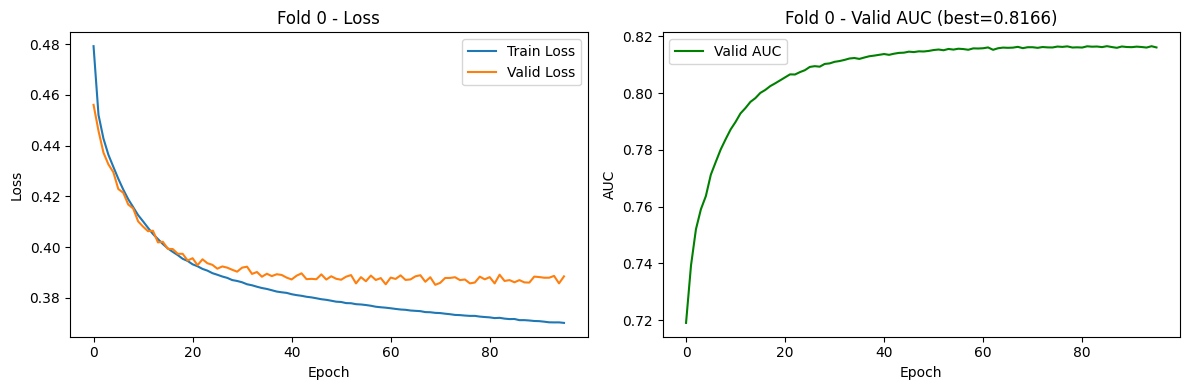

Fold 0 xong. Best valid AUC = 0.8166

FOLD 1


Epoch 1: train_loss=0.4799, val_loss=0.4502, val_auc=0.7202, val_acc=0.8034


Epoch 2: train_loss=0.4521, val_loss=0.4402, val_auc=0.7395, val_acc=0.8068


Epoch 3: train_loss=0.4426, val_loss=0.4314, val_auc=0.7529, val_acc=0.8108


Epoch 4: train_loss=0.4357, val_loss=0.4255, val_auc=0.7621, val_acc=0.8134


...

Epoch 91: train_loss=0.3711, val_loss=0.3832, val_auc=0.8167, val_acc=0.8355


Epoch 92: train_loss=0.3709, val_loss=0.3830, val_auc=0.8168, val_acc=0.8350


Epoch 93: train_loss=0.3708, val_loss=0.3847, val_auc=0.8170, val_acc=0.8347


Epoch 94: train_loss=0.3707, val_loss=0.3811, val_auc=0.8169, val_acc=0.8348


Epoch 95: train_loss=0.3705, val_loss=0.3831, val_auc=0.8170, val_acc=0.8352
Early stopping tại epoch 95


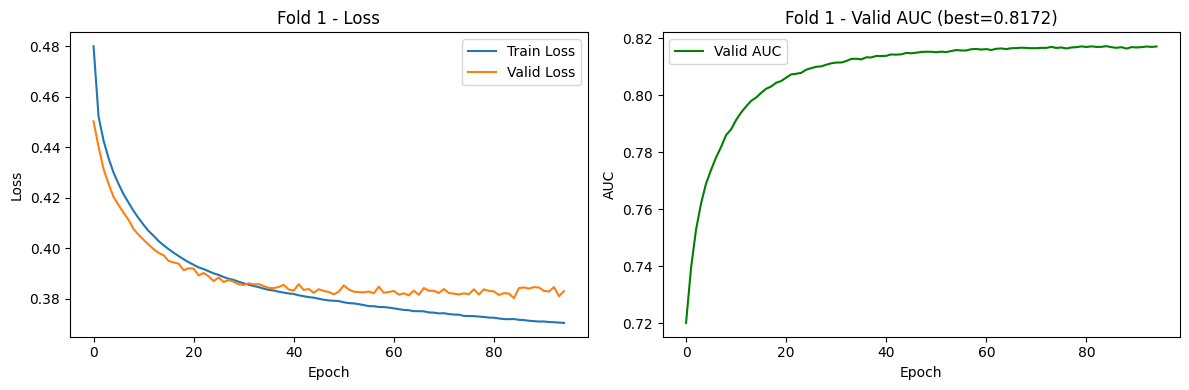

Fold 1 xong. Best valid AUC = 0.8172

FOLD 2


Epoch 1: train_loss=0.4787, val_loss=0.4573, val_auc=0.7235, val_acc=0.7990


Epoch 2: train_loss=0.4513, val_loss=0.4462, val_auc=0.7450, val_acc=0.8035


Epoch 3: train_loss=0.4416, val_loss=0.4388, val_auc=0.7573, val_acc=0.8074


Epoch 4: train_loss=0.4345, val_loss=0.4308, val_auc=0.7667, val_acc=0.8100


...

Epoch 92: train_loss=0.3708, val_loss=0.3869, val_auc=0.8201, val_acc=0.8322


Epoch 93: train_loss=0.3704, val_loss=0.3878, val_auc=0.8203, val_acc=0.8319


Epoch 94: train_loss=0.3702, val_loss=0.3880, val_auc=0.8201, val_acc=0.8321


Epoch 95: train_loss=0.3701, val_loss=0.3868, val_auc=0.8198, val_acc=0.8323


Epoch 96: train_loss=0.3702, val_loss=0.3874, val_auc=0.8202, val_acc=0.8321
Early stopping tại epoch 96


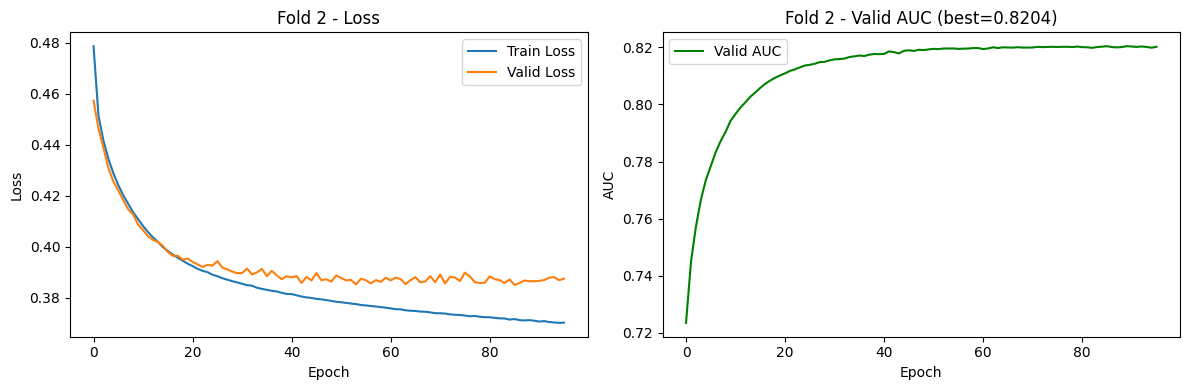

Fold 2 xong. Best valid AUC = 0.8204

FOLD 3


Epoch 1: train_loss=0.4802, val_loss=0.4554, val_auc=0.7177, val_acc=0.8020


Epoch 2: train_loss=0.4532, val_loss=0.4447, val_auc=0.7371, val_acc=0.8064


Epoch 3: train_loss=0.4445, val_loss=0.4385, val_auc=0.7489, val_acc=0.8095


Epoch 4: train_loss=0.4375, val_loss=0.4316, val_auc=0.7599, val_acc=0.8122


...

Epoch 83: train_loss=0.3718, val_loss=0.3839, val_auc=0.8188, val_acc=0.8354


Epoch 84: train_loss=0.3717, val_loss=0.3837, val_auc=0.8184, val_acc=0.8355


Epoch 85: train_loss=0.3715, val_loss=0.3833, val_auc=0.8191, val_acc=0.8354


Epoch 86: train_loss=0.3715, val_loss=0.3845, val_auc=0.8189, val_acc=0.8352


Epoch 87: train_loss=0.3713, val_loss=0.3833, val_auc=0.8183, val_acc=0.8353
Early stopping tại epoch 87


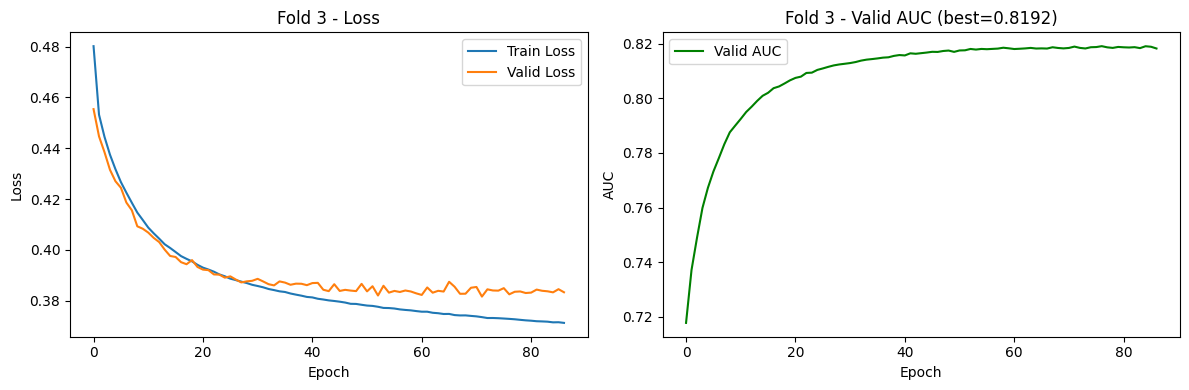

Fold 3 xong. Best valid AUC = 0.8192

FOLD 4


Epoch 1: train_loss=0.4830, val_loss=0.4546, val_auc=0.7195, val_acc=0.8010


Epoch 2: train_loss=0.4531, val_loss=0.4449, val_auc=0.7391, val_acc=0.8037


Epoch 3: train_loss=0.4435, val_loss=0.4371, val_auc=0.7521, val_acc=0.8073


Epoch 4: train_loss=0.4359, val_loss=0.4294, val_auc=0.7619, val_acc=0.8110


...

Epoch 86: train_loss=0.3708, val_loss=0.3850, val_auc=0.8183, val_acc=0.8326


Epoch 87: train_loss=0.3707, val_loss=0.3858, val_auc=0.8180, val_acc=0.8327


Epoch 88: train_loss=0.3706, val_loss=0.3854, val_auc=0.8184, val_acc=0.8329


Epoch 89: train_loss=0.3704, val_loss=0.3864, val_auc=0.8182, val_acc=0.8337


Epoch 90: train_loss=0.3703, val_loss=0.3846, val_auc=0.8185, val_acc=0.8330
Early stopping tại epoch 90


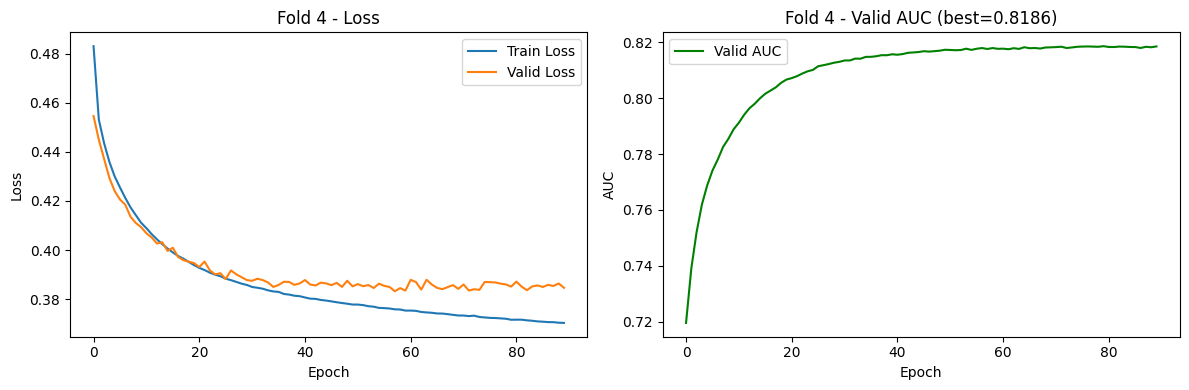

Fold 4 xong. Best valid AUC = 0.8186


In [10]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

trained_models = []       # giữ 5 model đã train xong, ngay trong RAM
all_histories = []        # giữ lịch sử loss/auc từng fold để vẽ biểu đồ
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
for i in range(5):
    print(f"\n{'='*50}\nFOLD {i}\n{'='*50}")

    # ---- Chuẩn bị data ----
    train_dataset = SAKTDataset(df_train_valid, config['num_concepts'], fold=i, is_train=True)
    valid_dataset = SAKTDataset(df_train_valid, config['num_concepts'], fold=i, is_train=False)
    train_loader = DataLoader(train_dataset, batch_size=config["batch_size"], shuffle=True)
    valid_loader = DataLoader(valid_dataset, batch_size=config["batch_size"], shuffle=False)

    # ---- Khởi tạo model mới (random init) cho mỗi fold ----
    model = SAKT(
        num_concepts=config['num_concepts'],
        seq_len=config['seq_len'],
        emb_size=config['emb_size'],
        num_attn_heads=config['num_attn_heads'],
        dropout=config['dropout'],
        num_en=config['num_en']
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=config.get('lr', 1e-3))

    # ---- Train fold này ----
    model, history = train_epoch(
        model, train_loader, valid_loader, optimizer, device,
        num_epochs=config.get('num_epochs', 50),
        patience=config.get('patience', 5)
    )

    trained_models.append(model)     # lưu model (đã load best checkpoint) vào RAM
    all_histories.append(history)

    # ---- Vẽ biểu đồ cho fold này ----
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["train_loss"], label="Train Loss")
    axes[0].plot(history["valid_loss"], label="Valid Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"Fold {i} - Loss")
    axes[0].legend()

    axes[1].plot(history["valid_auc"], label="Valid AUC", color="green")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AUC")
    axes[1].set_title(f"Fold {i} - Valid AUC (best={history['best_auc']:.4f})")
    axes[1].legend()

    plt.tight_layout()
    plt.show()          # hiển thị trực tiếp trong Kaggle notebook, không cần lưu file

    print(f"Fold {i} xong. Best valid AUC = {history['best_auc']:.4f}")

In [11]:
test_dataset = SAKTDataset(df_test, config['num_concepts'], fold=None, is_train=False)
test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)

test_results = []

for i, model in enumerate(trained_models):
    metrics = evaluate(model, test_loader, device, question_level=True)  # bật True nếu df_test có cột qidxs
    metrics["fold"] = i
    test_results.append(metrics)
    print(f"Fold {i} - Test: " + ", ".join(f"{k}={v:.4f}" for k, v in metrics.items() if k != "fold"))

Fold 0 - Test: auc=0.7658, acc=0.8101, rmse=0.3712, mae=0.2550, f1=0.8880, precision=0.8367, recall=0.9460


Fold 1 - Test: auc=0.7652, acc=0.8089, rmse=0.3714, mae=0.2585, f1=0.8871, precision=0.8371, recall=0.9433


Fold 2 - Test: auc=0.7664, acc=0.8100, rmse=0.3708, mae=0.2590, f1=0.8879, precision=0.8368, recall=0.9455


Fold 3 - Test: auc=0.7683, acc=0.8081, rmse=0.3715, mae=0.2603, f1=0.8857, precision=0.8415, recall=0.9349


Fold 4 - Test: auc=0.7680, acc=0.8103, rmse=0.3708, mae=0.2523, f1=0.8882, precision=0.8361, recall=0.9472


In [12]:
import numpy as np

metric_names = ["auc", "acc", "rmse", "mae", "f1", "precision", "recall"]

print(f"\n{'='*50}\nTỔNG HỢP KẾT QUẢ TEST (5-fold)\n{'='*50}")
for m in metric_names:
    values = [r[m] for r in test_results]
    print(f"{m.upper():10s}: {np.mean(values):.4f} ± {np.std(values):.4f}")


TỔNG HỢP KẾT QUẢ TEST (5-fold)
AUC       : 0.7668 ± 0.0012
ACC       : 0.8095 ± 0.0009
RMSE      : 0.3711 ± 0.0003
MAE       : 0.2570 ± 0.0029
F1        : 0.8874 ± 0.0009
PRECISION : 0.8377 ± 0.0019
RECALL    : 0.9434 ± 0.0044


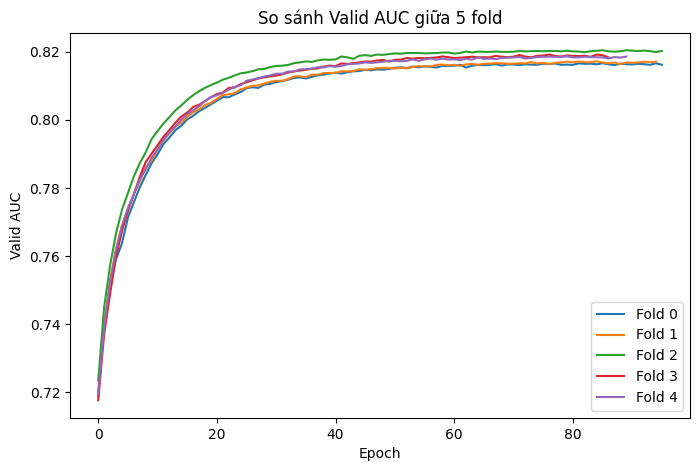

In [13]:
plt.figure(figsize=(8, 5))
for i, history in enumerate(all_histories):
    plt.plot(history["valid_auc"], label=f"Fold {i}")
plt.xlabel("Epoch")
plt.ylabel("Valid AUC")
plt.title("So sánh Valid AUC giữa 5 fold")
plt.legend()
plt.show()